In [1]:
import numpy
import pandas
import seaborn

from matplotlib import pyplot

from fitting import TIMESERIES_TABLE_PATH
from realistic import PARAMS

/home/anm1u24/.cache/pypoetry/virtualenvs/slrv-m033ZCIA-py3.13/lib/python3.13/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/anm1u24/.cache/pypoetry/virtualenvs/slrv-m033ZCIA-py3.13/lib/python3.13/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/anm1u24/.cache/pypoetry/virtualenvs/slrv-m033ZCIA-py3.13/lib/python3.13/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 366 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


In [2]:
pyplot.rcParams["figure.figsize"] = [12.8, 9.6]

In [3]:
def err(obs, model):
    scale = numpy.abs(obs)
    scale[scale == 0] = 1
    return numpy.abs(obs - model) / scale

In [4]:
params = {
    'a': 'fitted_a',
    'b': 'fitted_b',
    'e': 'fitted_e',
    'periapsis_phase': 'fitted_periapsis_phase',
    'Macc': 'fitted_Macc',
    'Porb': 'fitted_porb',
    'tau_eff': 'fitted_tau_eff',
}

In [5]:
results = pandas.read_pickle(TIMESERIES_TABLE_PATH)

In [6]:
results

,a,e,periapsis_phase,Macc,Porb,tau_eff,Mcomp,Rcomp,b,b_max,...,realistic_idx,fitted_a,fitted_b,fitted_b_max,fitted_i,fitted_Macc,fitted_e,fitted_periapsis_phase,fitted_porb,fitted_tau_eff
0,1.264855,0,0,15.416667,128.238126,0.178397,1.0,1.0,8.826807e-14,6.300033,...,46781,2.086854,1.517061,5.420260,1.570032,19.466717,0.322194,5.898529,243.395401,0.203248
1,0.175751,0,0,10.208333,8.038497,0.044278,1.0,1.0,1.451842e+01,18.475124,...,70182,0.048967,83.155026,141.315936,1.514483,1.005227,0.434804,0.103220,2.794898,0.068911
2,2.947052,0,0,11.250000,527.973367,0.330443,1.0,1.0,1.577234e-13,5.064658,...,25217,1.919650,16.284454,16.595678,1.568267,2.157983,0.575578,5.123581,546.671718,0.086467
3,0.132571,0,0,19.583333,3.886101,0.044329,1.0,1.0,4.567868e+00,15.525785,...,84039,0.534781,0.418793,7.502562,1.570236,27.743113,0.298024,4.859069,26.643731,0.084960
4,0.268270,0,0,27.916667,9.438032,0.047807,1.0,1.0,5.442348e+00,9.552437,...,11780,0.536038,1.592963,7.053886,1.568514,25.575814,0.096542,3.473749,27.806636,0.087162
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0.268270,0,0,22.708333,10.423296,0.063580,1.0,1.0,3.349435e-14,10.482347,...,25306,2.135387,1.794959,4.306118,1.569614,20.917368,0.278442,4.019830,243.455309,0.199807
4996,0.100000,0,0,10.208333,3.450070,0.039217,1.0,1.0,1.637033e+01,24.170427,...,55518,0.194613,10.665469,17.942151,1.555753,10.867399,0.115856,5.648179,9.102877,0.058971
4997,2.947052,0,0,5.000000,754.404785,0.441085,1.0,1.0,2.365851e-13,7.096988,...,9571,40.269636,0.713336,3.066544,1.570756,3.654100,0.742045,4.001020,43266.038170,2.295306
4998,21.209509,0,0,28.958333,6518.317655,0.936674,1.0,1.0,2.637284e-13,1.944370,...,36389,16.050877,1.652420,3.284584,1.570587,11.007426,0.618424,1.506651,6778.312788,0.776741


In [7]:
def plot_density(param):
    pyplot.hist2d(results[param], results[params[param]], bins=50, cmap='viridis',
                norm=pyplot.matplotlib.colors.LogNorm())
    pyplot.xlabel(param)
    pyplot.ylabel(params[param])
    pyplot.colorbar(label='Density')
    pyplot.show()

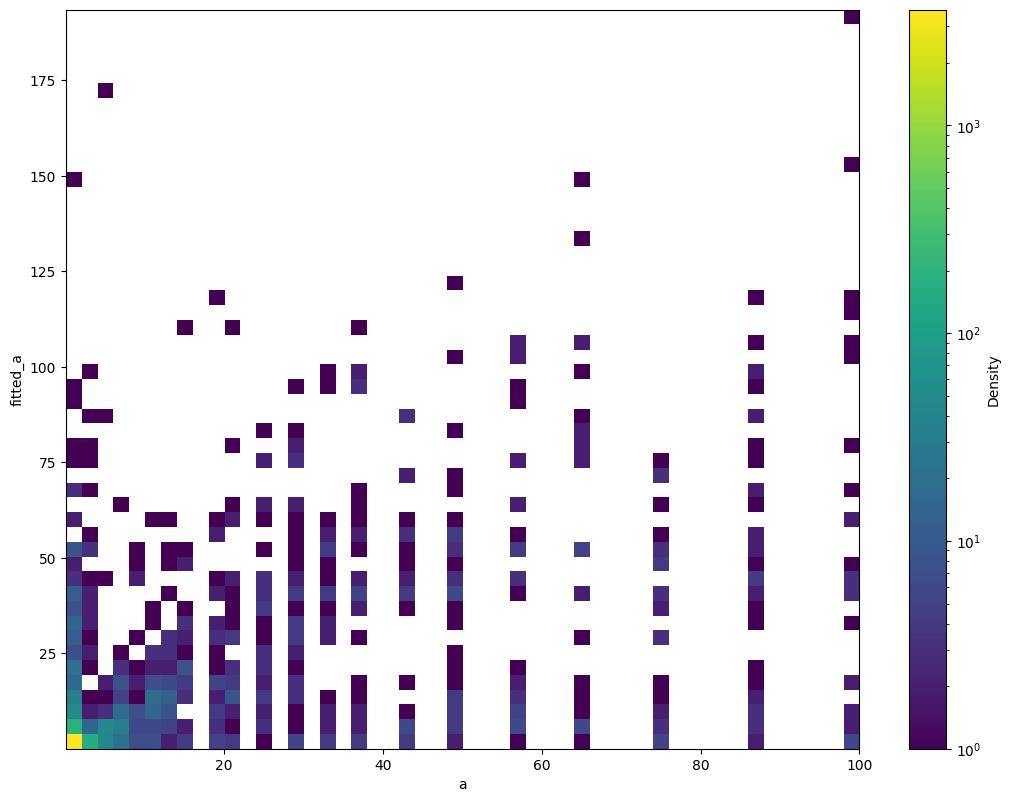

In [8]:
plot_density('a')

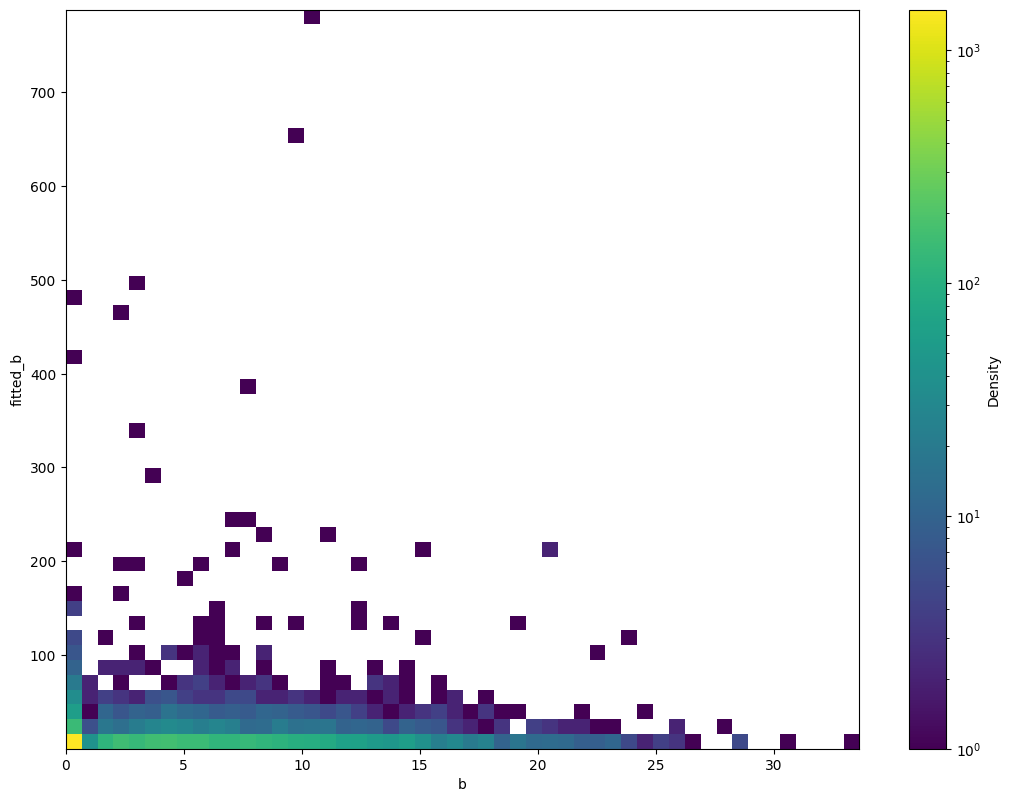

In [9]:
plot_density('b')

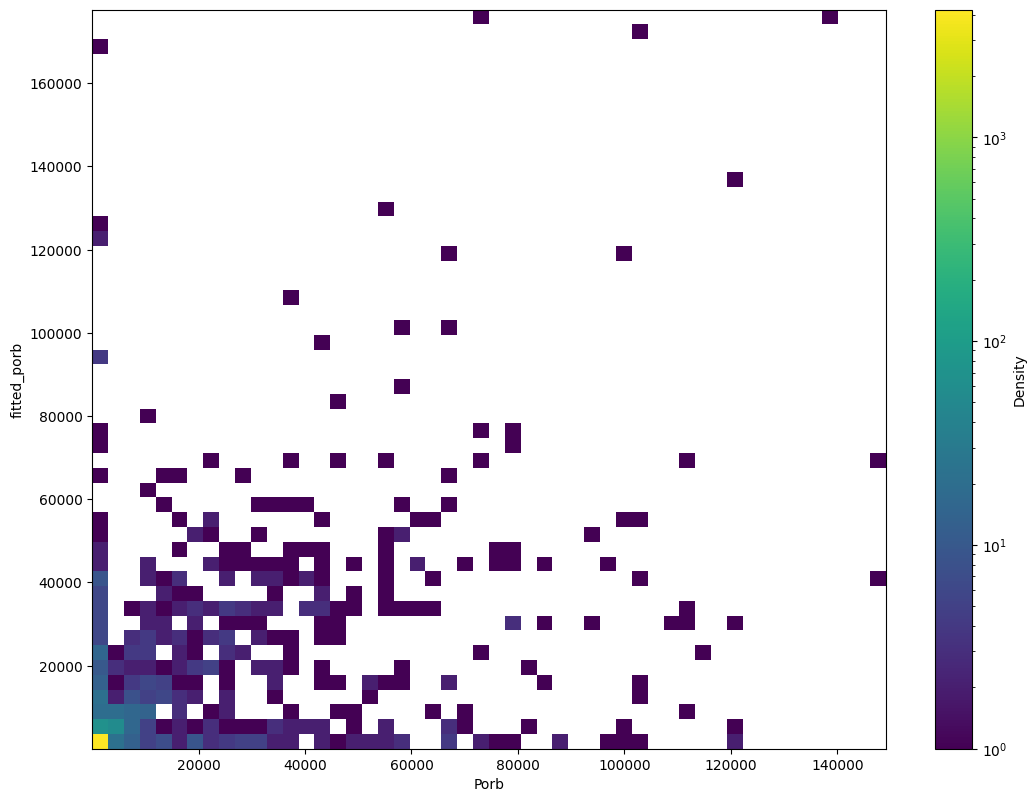

In [10]:
plot_density('Porb')

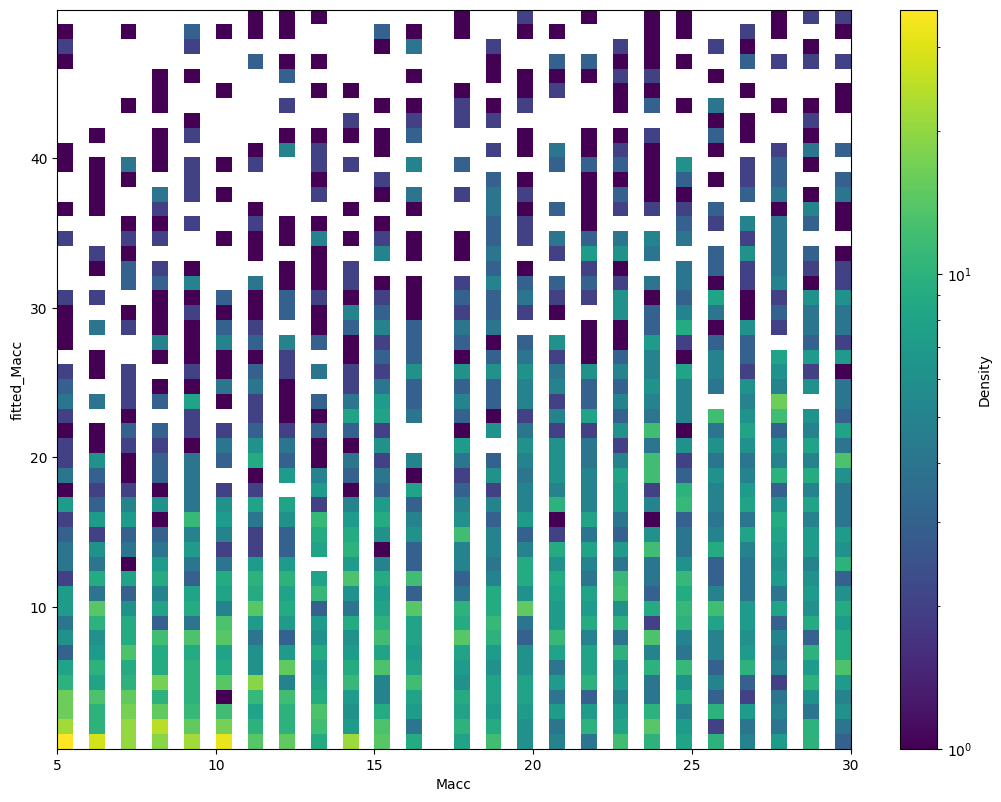

In [11]:
plot_density('Macc')

ValueError: autodetected range of [nan, nan] is not finite

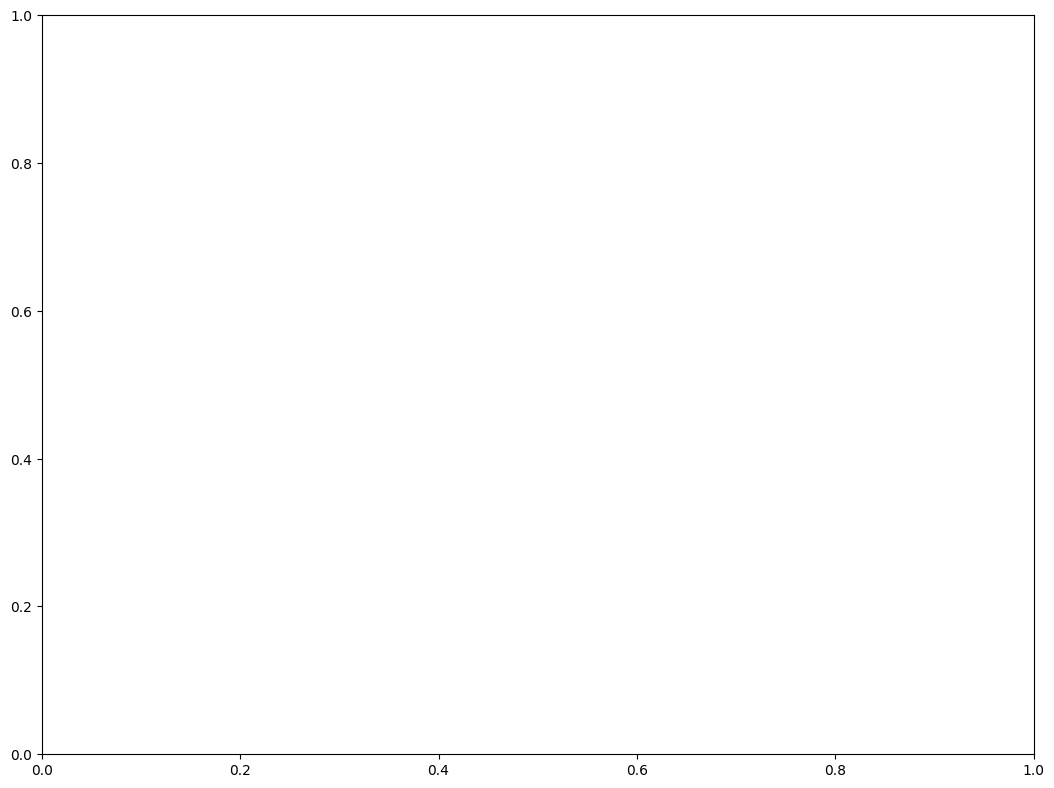

In [12]:
plot_density('tau_eff')

In [ ]:
def plot_relation(x, y='RV accuracy', logx=True, logy=True, bins=20):
    for cadence, cadence_group in results.groupby('cadence'):
        baselines = numpy.sort(cadence_group['baseline'].unique())
        fig, axes = pyplot.subplots(1, len(baselines), figsize=(6 * len(baselines), 5), sharey=True)
        if len(baselines) == 1:
            axes = [axes]
        for ax, baseline in zip(axes, baselines):
            subset = cadence_group[cadence_group['baseline'] == baseline]
            xdata = subset[x]
            ydata = subset[y]
            diff = numpy.abs(subset[x] - subset[params[x]]) / subset[x]
            # Bin edges
            if logx:
                xbins = numpy.logspace(numpy.log10(xdata.min()), numpy.log10(xdata.max()), bins + 1)
            else:
                xbins = numpy.linspace(xdata.min(), xdata.max(), bins + 1)
            if logy:
                ybins = numpy.logspace(numpy.log10(ydata.min()), numpy.log10(ydata.max()), bins + 1)
            else:
                ybins = numpy.linspace(ydata.min(), ydata.max(), bins + 1)
            # Digitize to get bin indices
            xinds = numpy.digitize(xdata, xbins) - 1
            yinds = numpy.digitize(ydata, ybins) - 1
            mean_diff = numpy.full((bins, bins), numpy.nan)
            for i in range(bins):
                for j in range(bins):
                    mask = (xinds == i) & (yinds == j)
                    if numpy.any(mask):
                        mean_diff[i, j] = diff[mask].mean()
            # Use log scale for colors
            mesh = ax.pcolormesh(
                xbins, ybins, mean_diff.T,
                cmap='viridis',
                norm=pyplot.matplotlib.colors.LogNorm(vmin=numpy.nanmin(mean_diff), vmax=numpy.nanmax(mean_diff))
            )
            ax.set_title(f'Cadence: {cadence}, Baseline: {baseline}')
            ax.set_xlabel(x)
            ax.set_ylabel(y)
            if logx:
                ax.set_xscale('log')
            if logy:
                ax.set_yscale('log')
            fig.colorbar(mesh, ax=ax, label='Mean absolute difference (%)')
        pyplot.tight_layout()
        pyplot.show()

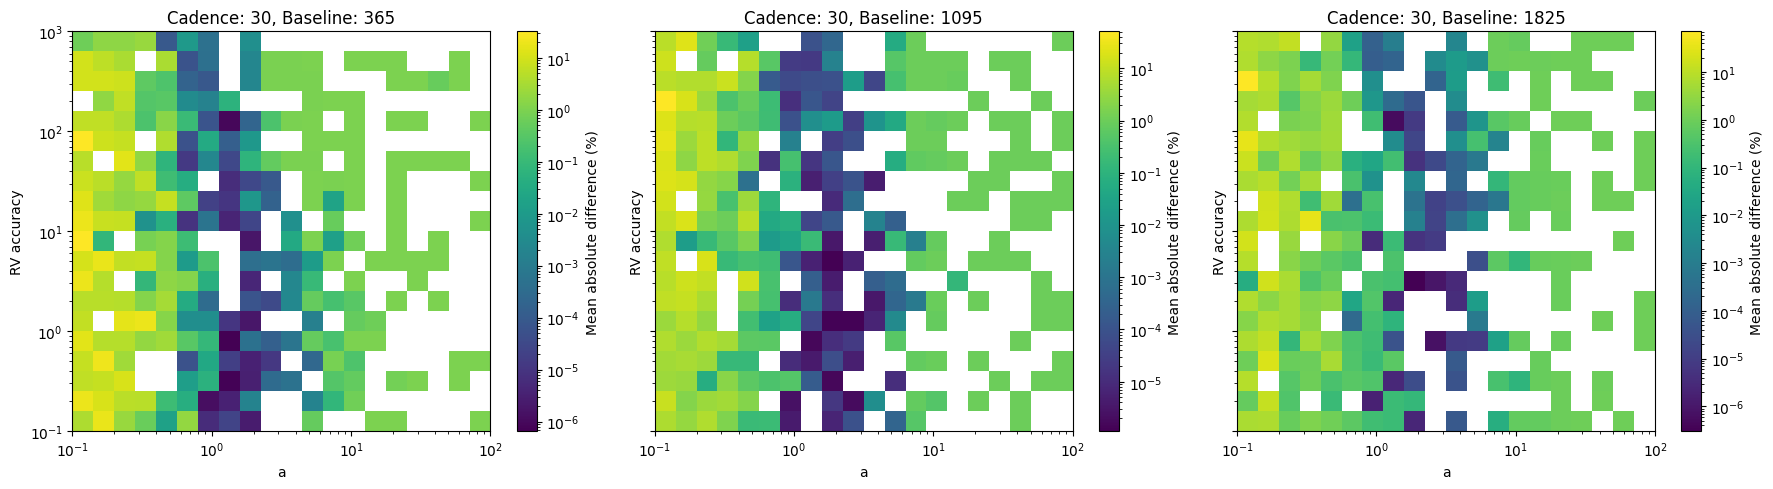

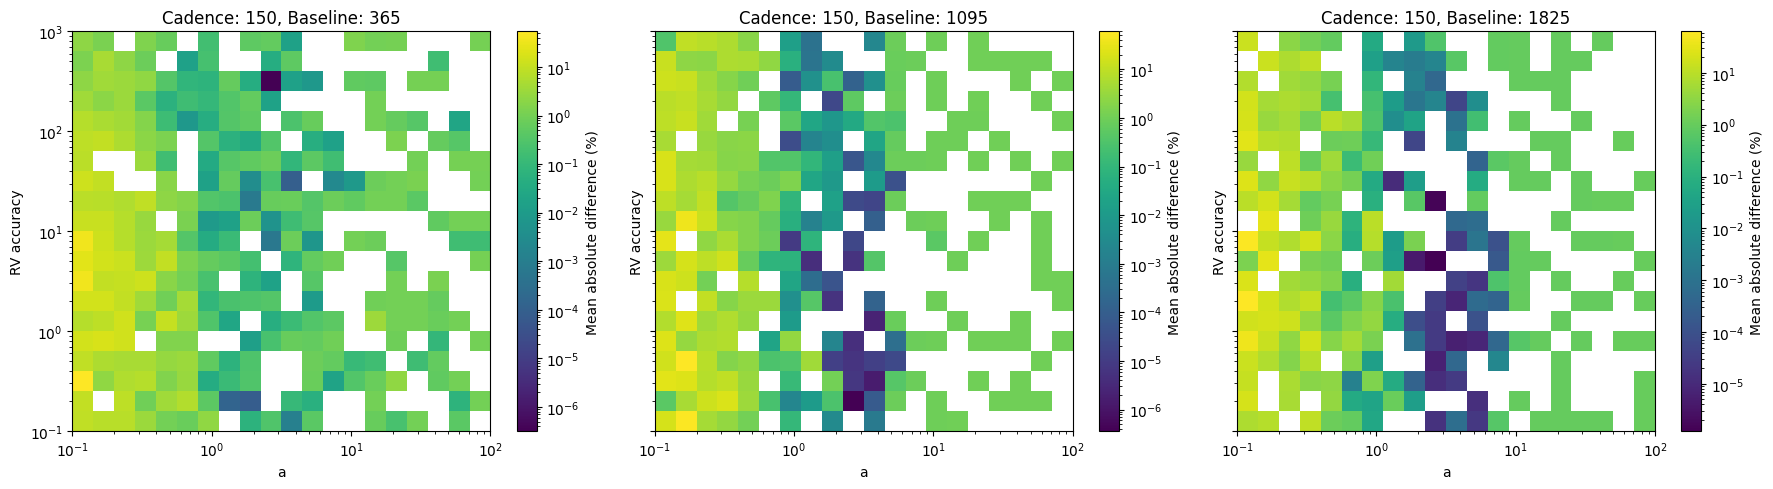

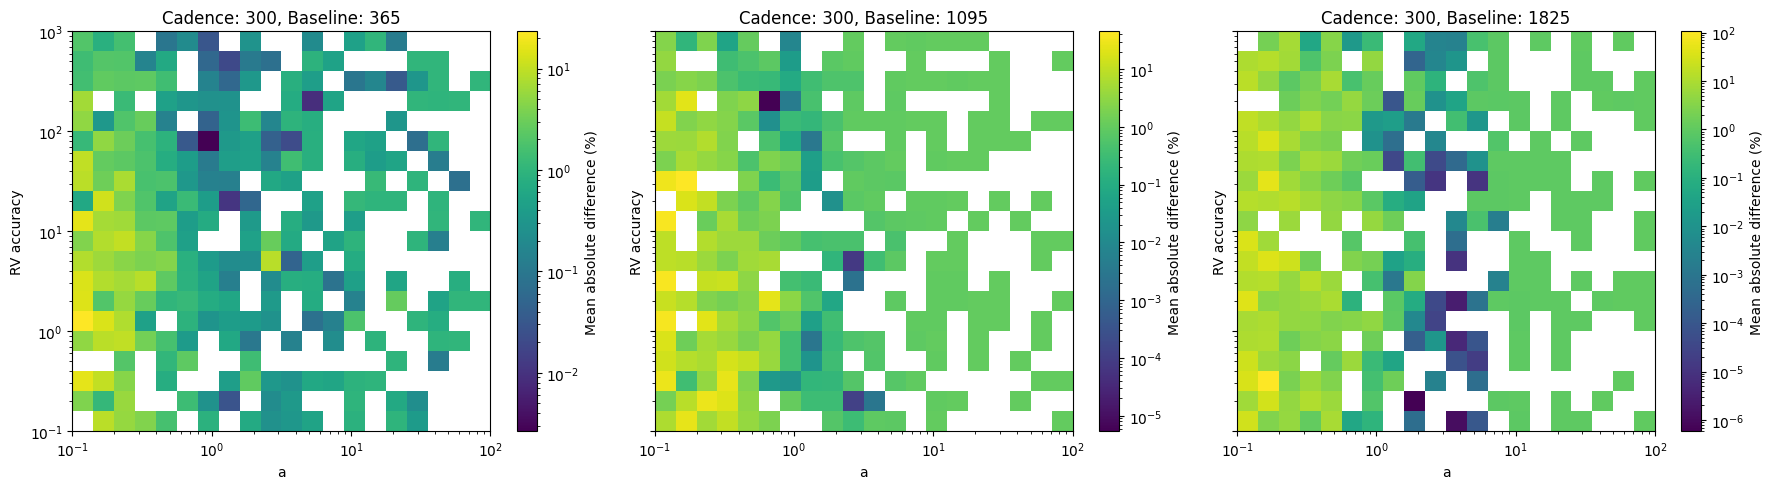

In [ ]:
plot_relation('a')

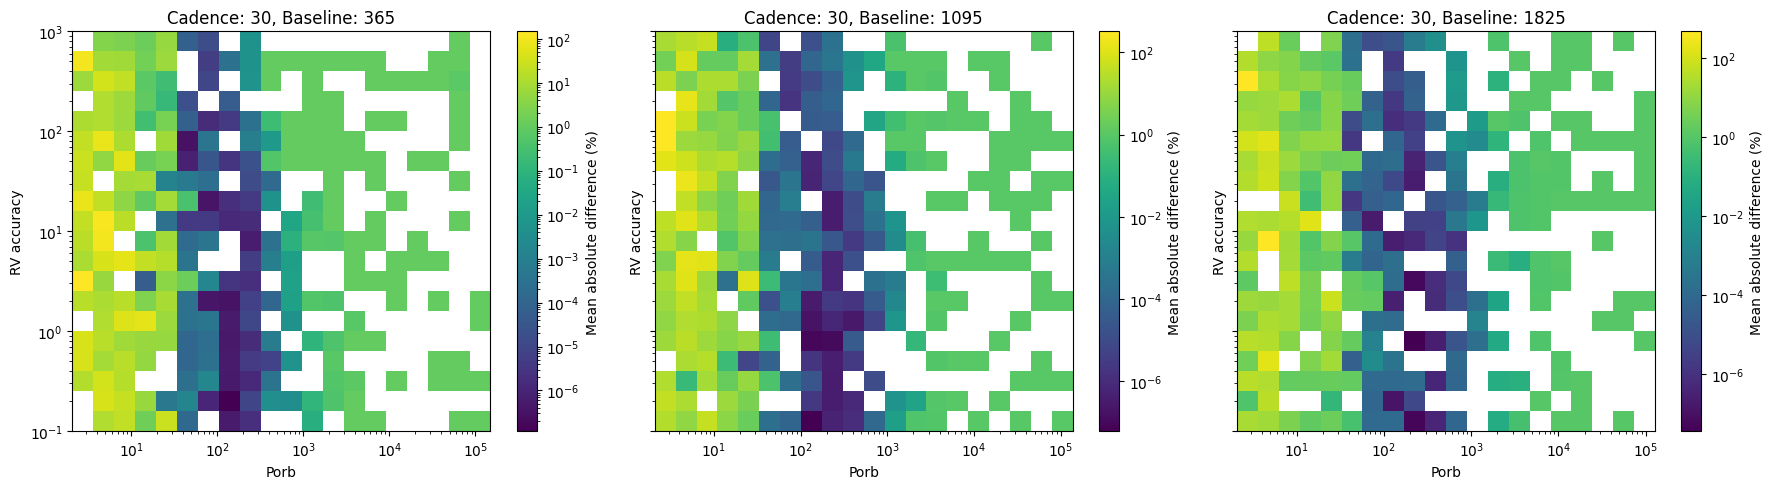

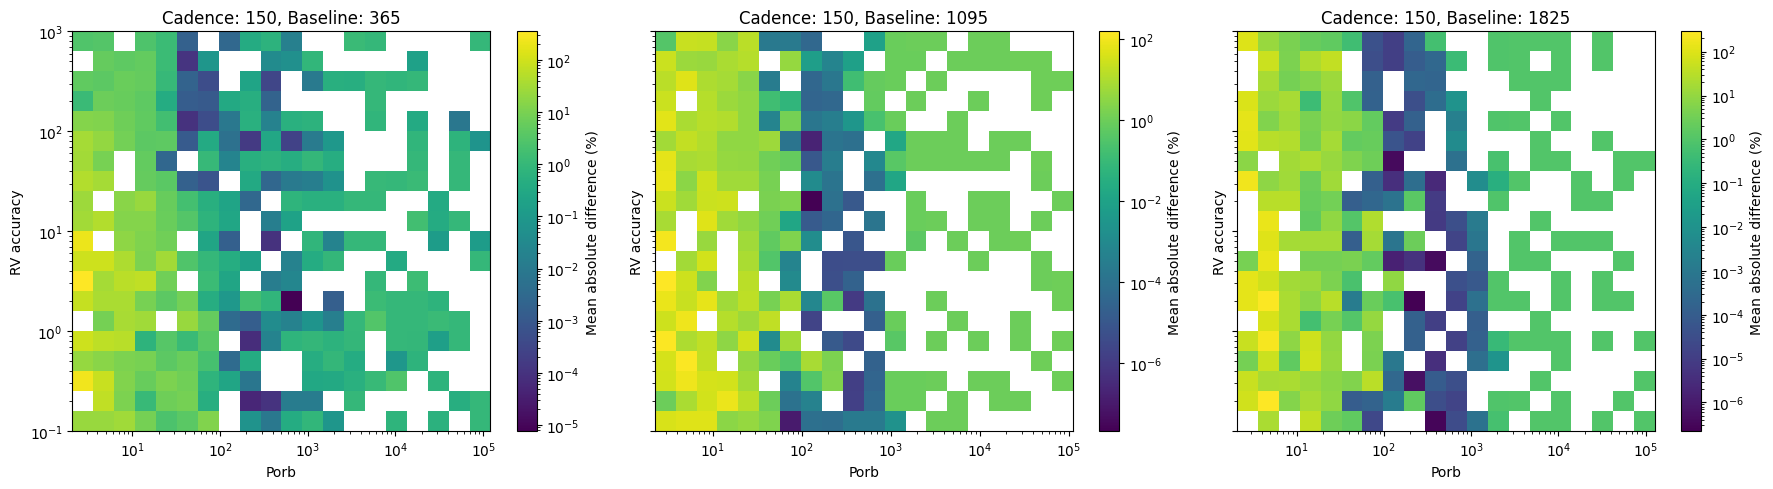

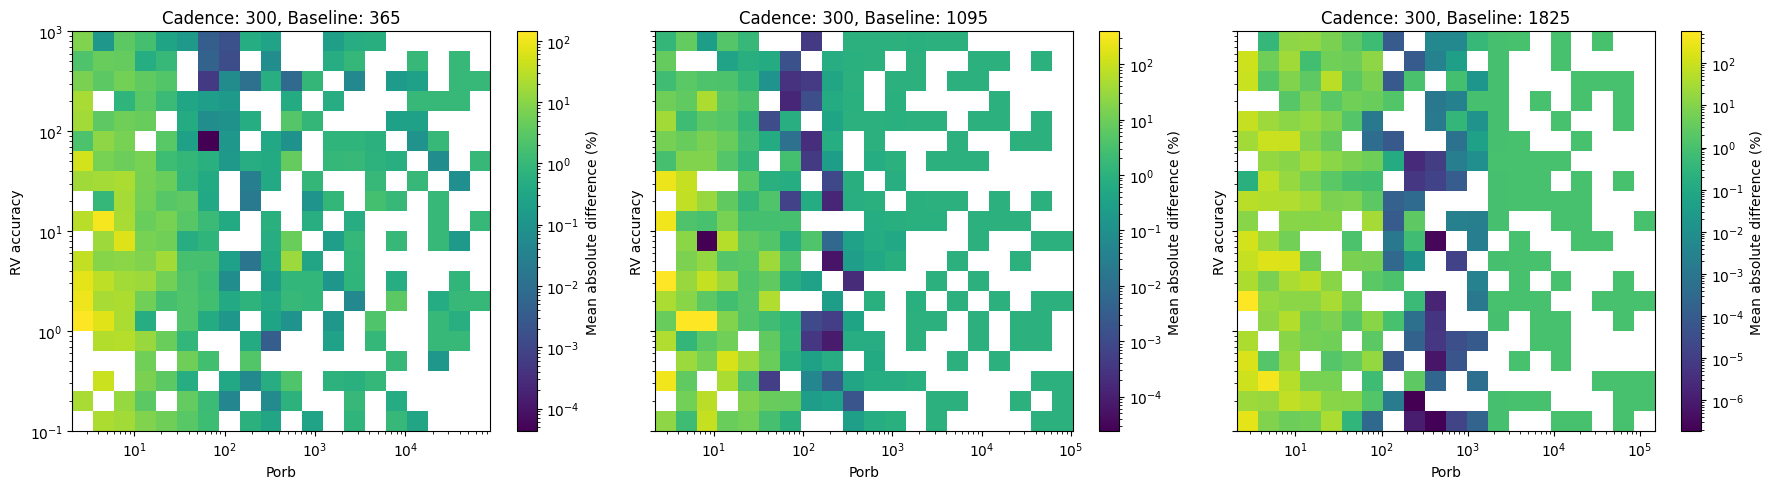

In [ ]:
plot_relation('Porb')

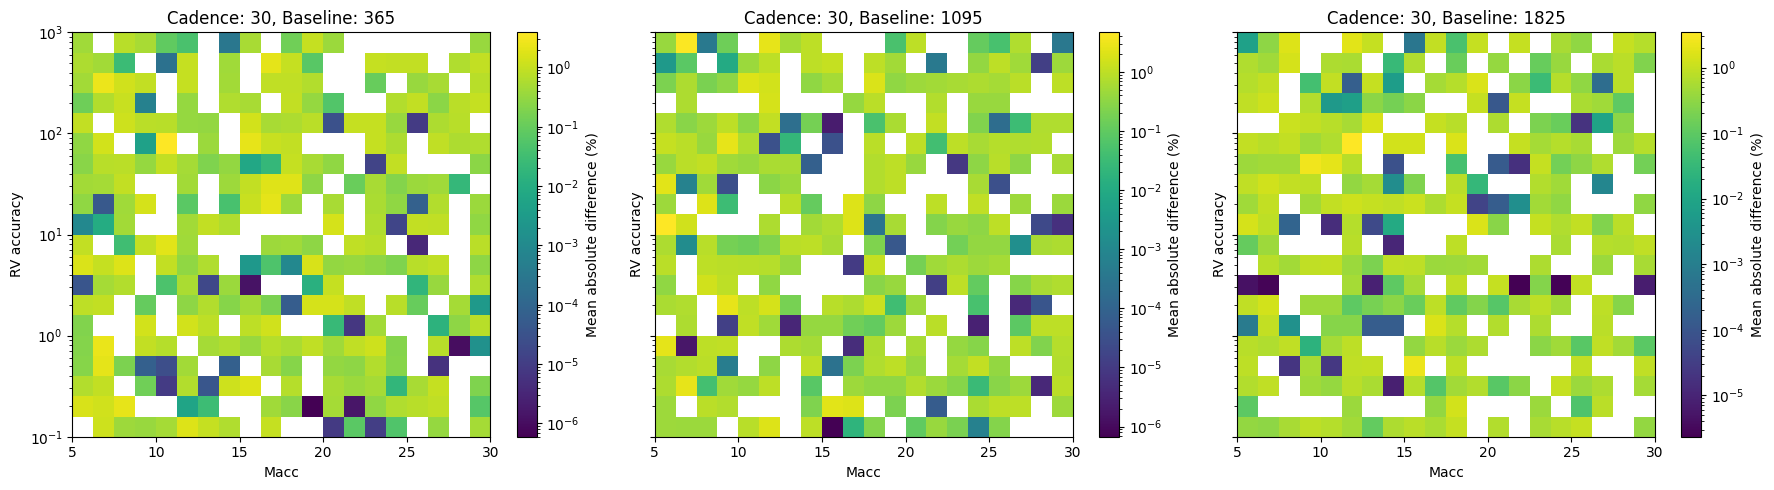

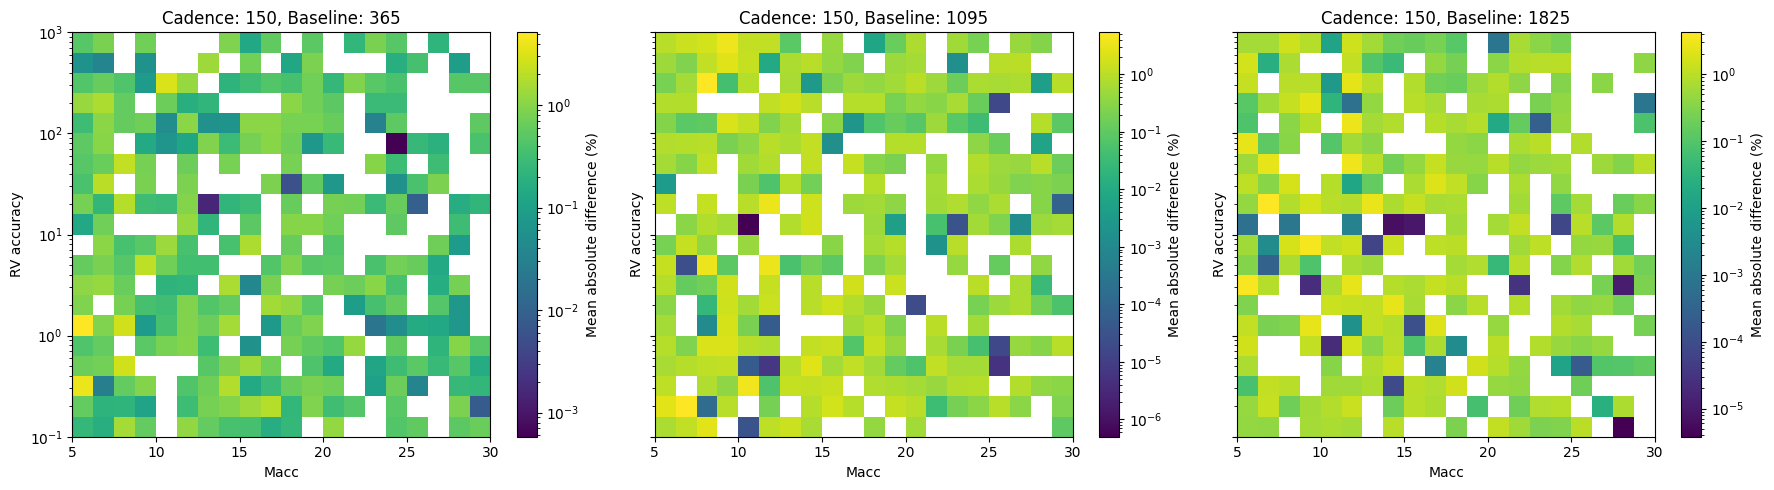

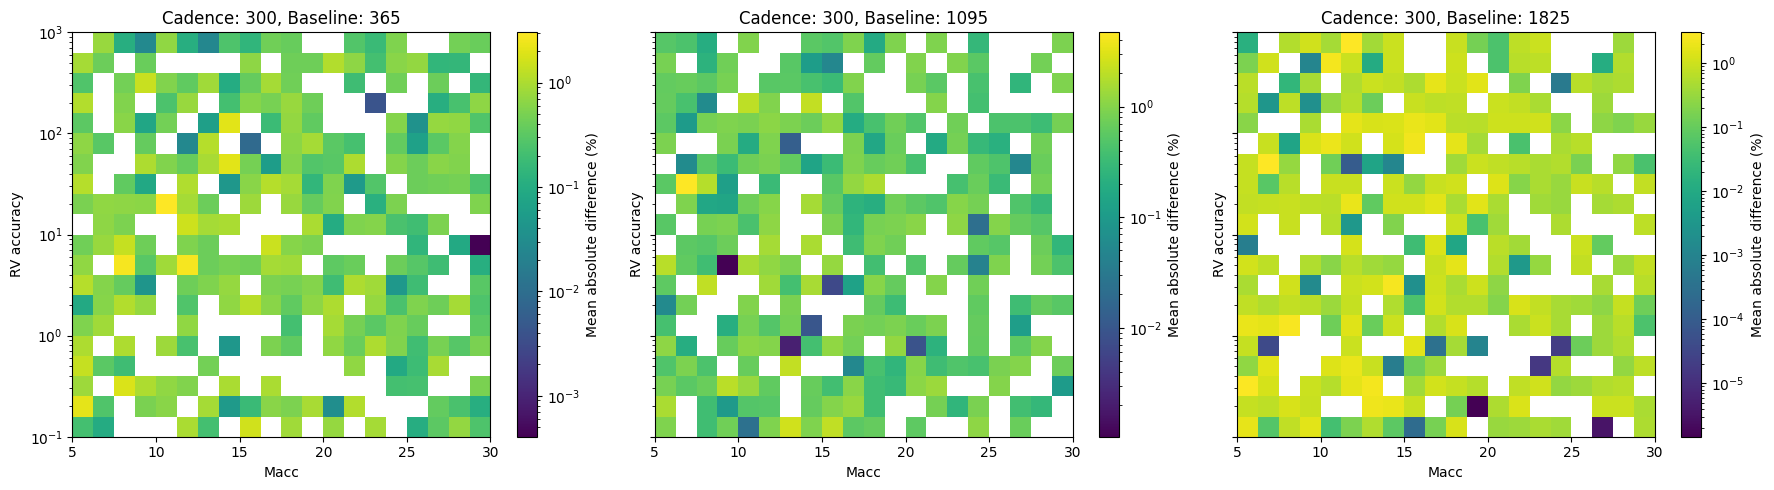

In [ ]:
plot_relation('Macc', logx=False)

In [ ]:
plot_relation('b', logx=False)

ValueError: Invalid vmin or vmax

Error in callback <function _draw_all_if_interactive at 0x7f5c7ddfaf20> (for post_execute), with arguments args (),kwargs {}:


ValueError: Invalid vmin or vmax

ValueError: Invalid vmin or vmax

<Figure size 1800x500 with 4 Axes>